# Linear Elastic Fracture Mechanics

*Authors:*
 - *Laura De Lorenzis (ETH Zürich)*
 - *Veronique Lazarus (ENSTA, IPP)*
 - *Corrado Maurini (Sorbonne Université, corrado.maurini@sorbonne-universite.fr)*

This notebook takes the elastic solution of `01-LinearElasticity.ipynb` and reads
the two quantities of linear elastic fracture mechanics out of it: the stress
intensity factor $K_I$ and the energy release rate $G$.

$K_I$ is obtained twice, by extrapolating the crack opening displacement and by
extrapolating the stress ahead of the tip. $G$ is obtained twice as well, by a
finite difference of the potential energy with respect to the crack length, and
by the G-theta method, which is the same derivative taken on a fixed mesh.
Irwin's formula $G = K_I^2/E$ in plane stress links the two.

In [13]:
import sys
sys.path.append("../utils")

# Import required libraries
import matplotlib.pyplot as plt
import numpy as np

import dolfinx.fem as fem
import dolfinx.mesh as mesh
import dolfinx.io as io
import dolfinx.plot as plot
import dolfinx.fem.petsc
import ufl

from mpi4py import MPI
from petsc4py import PETSc
from petsc4py.PETSc import ScalarType

plt.rcParams["figure.figsize"] = (6, 3)

outdir = "output"
from pathlib import Path
Path(outdir).mkdir(parents=True, exist_ok=True)

# Asymptotic field and SIF ($K_I$)

Let us first get the elastic solution for a given crack length

The potential energy for Lcrack=3.000e-01 is -4.066e-01


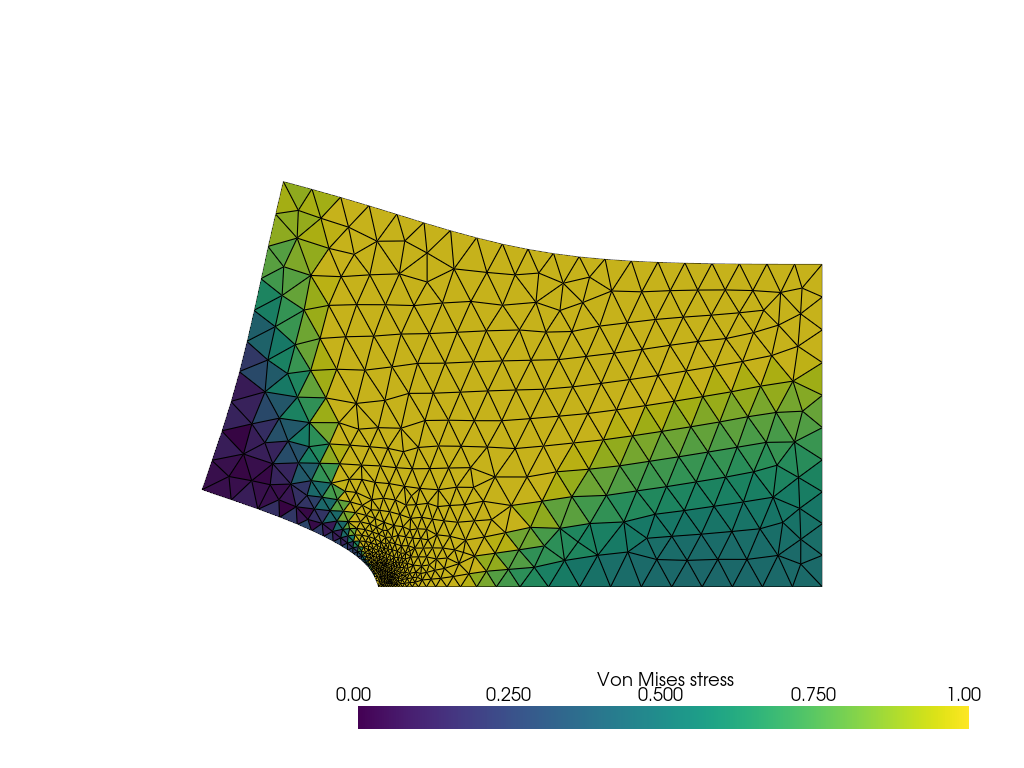

In [14]:
from elastic_solver import solve_elasticity

Lx = 1.
Ly = 0.5
Lcrack = 0.3
lc = .05
dist_min = .1
dist_max = .3
uh, energy, sigma_ufl = solve_elasticity(Lx=Lx,
                                         Ly=Ly,
                                         Lcrack=Lcrack,
                                         lc=lc,
                                         refinement_ratio=20,
                                         dist_min=dist_min,
                                         dist_max=dist_max,
                                         verbosity=1)

from plots import warp_plot_2d
import pyvista
pyvista.set_jupyter_backend("static")

sigma_iso = 1./3 * ufl.tr(sigma_ufl) * ufl.Identity(len(uh))
sigma_dev = sigma_ufl - sigma_iso
von_Mises = ufl.sqrt(3./2 * ufl.inner(sigma_dev, sigma_dev))
V_dg = fem.functionspace(uh.function_space.mesh, ("DG", 0))
stress_expr = fem.Expression(von_Mises, V_dg.element.interpolation_points)
vm_stress = fem.Function(V_dg)
vm_stress.interpolate(stress_expr)

plotter = warp_plot_2d(uh, cell_field=vm_stress, field_name="Von Mises stress",
                       factor=.1, show_edges=True, clim=[0.0, 1.0],
                       show_scalar_bar=True)
if not pyvista.OFF_SCREEN:
    plotter.show()
else:
    figure = plotter.screenshot(f"{outdir}/VonMises.png")

## Crack opening displacement (COD)

Let us get the vertical displacement at the crack lip.

`evaluate_function`, from `utils/evaluation.py`, gives the values of a finite
element function at arbitrary points, in serial and in parallel alike. The
points are given as an array of shape `(number of points, 2)`.

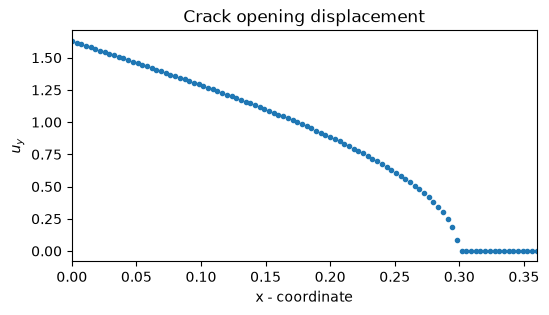

In [15]:
from evaluation import evaluate_function

xs = np.linspace(0, Lcrack * 1.2, 100)
points = np.zeros((xs.size, 2))
points[:, 0] = xs
us = evaluate_function(uh, points)[:, 1]

plt.plot(xs, us, ".")
plt.xlim([0., Lcrack * 1.2])
plt.xlabel("x - coordinate")
plt.ylabel(r"$u_y$")
plt.title("Crack opening displacement")
plt.savefig(f"{outdir}/COD.png")

As detailed in the lecture notes, we can estimate the value of the stress
intensity factor $K_I$ by extrapolating $u_y\,\frac{2\mu}{\kappa+1}\sqrt{2\pi/r}$
towards the tip, $r\to 0$.

K_I from the COD is 1.7027


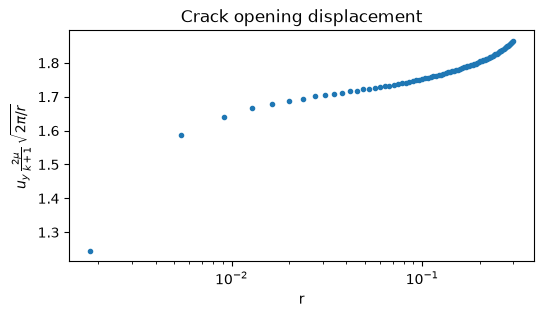

In [16]:
# the distance to the tip, on the crack faces only: ahead of the tip the
# opening is zero and the extrapolation is meaningless
behind = xs < Lcrack
r = Lcrack - xs[behind]

nu = 0.3
E = 1.0
mu = E / (2.0 * (1.0 + nu))
kappa = (3 - nu) / (1 + nu)
factor = 2 * mu / (kappa + 1)

KI_cod = us[behind] * np.sqrt(2 * np.pi / r) * factor

plt.semilogx(r, KI_cod, ".")
plt.xlabel("r")
plt.ylabel(r"${u_y} \,\frac{2\mu}{k+1} \,\sqrt{2\pi/r}$")
plt.title("Crack opening displacement")
plt.savefig(f"{outdir}/KI-COD.png")

# the plateau of the curve above: far enough from the tip for the mesh to
# resolve the field, close enough for the asymptotic term to dominate
h_tip = lc / 20  # the mesh size at the tip, lc divided by refinement_ratio
plateau = np.logical_and(r > 2 * h_tip, r < Lcrack / 4)
KI_from_cod = KI_cod[plateau].mean()
print(f"K_I from the COD is {KI_from_cod:2.4f}")

The curve flattens between the mesh size at the tip and a quarter of the crack
length: that plateau is the stress intensity factor. We estimate
$K_I\simeq 1.7$.

## Stress at the crack tip

Let us get the stress around the crack tip

In [17]:
xs = np.linspace(Lcrack, 2 * Lcrack, 1000)
points = np.zeros((xs.size, 2))
points[:, 0] = xs
r = (xs - Lcrack)

# the displacement is P1, so the stress is constant over each cell: a DG0
# function holds it exactly, with no smoothing of the singularity
sigma_xx_expr = fem.Expression(sigma_ufl[0, 0], V_dg.element.interpolation_points)
sigma_xx = fem.Function(V_dg)
sigma_xx.interpolate(sigma_xx_expr)
sigma_xx_values = evaluate_function(sigma_xx, points)

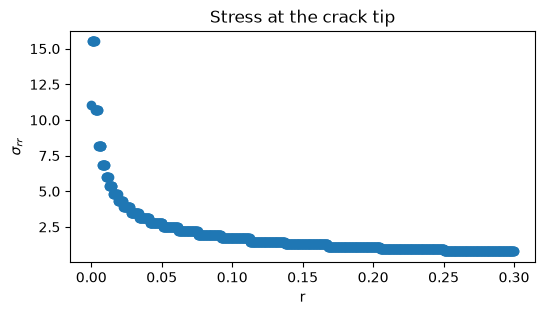

In [18]:
plt.plot(r, sigma_xx_values[:, 0], "o")
plt.xlabel("r")
plt.ylabel(r"$\sigma_{rr}$")
plt.title("Stress at the crack tip")
plt.savefig(f"{outdir}/stress.png")

As detailed in the lecture notes, we can estimate the value of the stress
intensity factor $K_I$ by extrapolating $\sigma_{rr} \sqrt{2\pi r}$

K_I from the stress is 1.5075


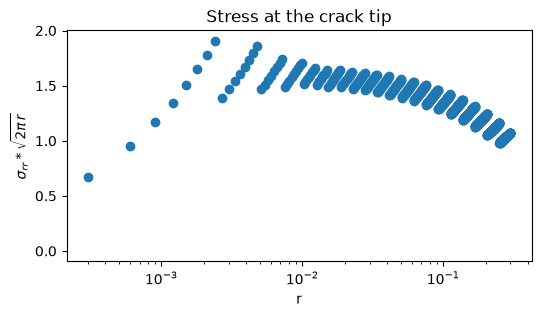

In [19]:
KI_stress = sigma_xx_values[:, 0] * np.sqrt(2 * np.pi * r)

plt.semilogx(r, KI_stress, "o")
plt.xlabel("r")
plt.ylabel(r"$\sigma_{rr}*\sqrt{2\pi\,r}$")
plt.title("Stress at the crack tip")
plt.savefig(f"{outdir}/KI-stress.png")

plateau = np.logical_and(r > 2 * h_tip, r < Lcrack / 4)
print(f"K_I from the stress is {KI_stress[plateau].mean():2.4f}")

This second estimate agrees with the one read on the crack opening, but it is
far less precise: the stress is the derivative of the field the computation
solves for, it is constant over each cell, and it is the quantity that the
singularity makes unbounded.

From Irwin's formula in plane stress, we get the energy release rate (ERR)

In [20]:
KI_estimate = KI_from_cod
G_estimate = KI_estimate ** 2 / E  # Irwin's formula in plane stress
print(f"ERR estimate is {G_estimate:2.4f}")

ERR estimate is 2.8991


# The elastic energy release rate

## Naïf method: finite difference of the potential energy

Let us first calculate the potential energy for several crack lengths. We
multiply the result by `2` to account for the symmetry when comparing with the
$K_I$ estimate above.

In [21]:
Ls = np.linspace(Lcrack * .7, Lcrack * 1.3, 10)
energies = np.zeros_like(Ls)
Gs = np.zeros_like(Ls)
for (i, L) in enumerate(Ls):
    uh, energies[i], _ = solve_elasticity(Lx=Lx,
                                          Ly=Ly,
                                          Lcrack=L,
                                          lc=.05,
                                          refinement_ratio=10,
                                          dist_min=.1,
                                          dist_max=1.,
                                          verbosity=1)

energies = energies * 2

The potential energy for Lcrack=2.100e-01 is -3.094e-01
The potential energy for Lcrack=2.300e-01 is -3.254e-01
The potential energy for Lcrack=2.500e-01 is -3.440e-01
The potential energy for Lcrack=2.700e-01 is -3.659e-01
The potential energy for Lcrack=2.900e-01 is -3.914e-01
The potential energy for Lcrack=3.100e-01 is -4.209e-01
The potential energy for Lcrack=3.300e-01 is -4.549e-01
The potential energy for Lcrack=3.500e-01 is -4.932e-01
The potential energy for Lcrack=3.700e-01 is -5.374e-01
The potential energy for Lcrack=3.900e-01 is -5.872e-01


We can estimate the ERR by taking the finite-difference approximation of the derivative

The ERR by finite differences is 2.9415


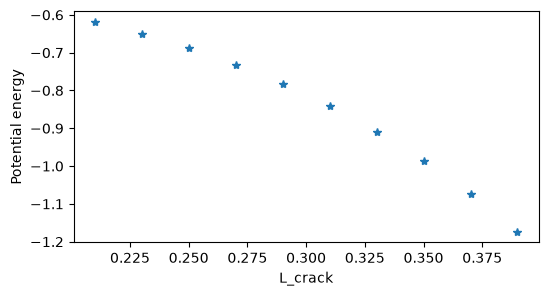

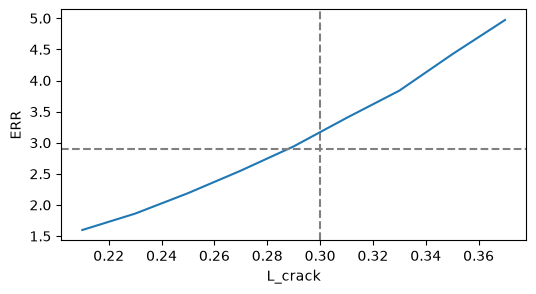

In [22]:
ERR_naif = -np.diff(energies) / np.diff(Ls)

plt.figure()
plt.plot(Ls, energies, "*")
plt.xlabel("L_crack")
plt.ylabel("Potential energy")
plt.figure()
plt.plot(Ls[0:-1], ERR_naif, "-")
plt.ylabel("ERR")
plt.xlabel("L_crack")
plt.axhline(G_estimate, linestyle='--', color="gray")
plt.axvline(Lcrack, linestyle='--', color="gray")

# the value at the crack length of the sections above
mid = np.argmin(np.abs(0.5 * (Ls[:-1] + Ls[1:]) - Lcrack))
print(f"The ERR by finite differences is {ERR_naif[mid]:2.4f}")

# G-theta method: domain derivative

This function implements the G-theta method to compute the ERR as described in
the lecture notes (see https://gitlab.com/newfrac/CORE-school/newfrac-core-numerics/-/blob/master/Core_School_numerical_NOTES.pdf?ref_type=heads).

We first create by an auxiliary computation a suitable theta-field.

To this end, we solve an auxiliary problem for finding a $\theta$-field which is
equal to $1$ in a disk around the crack tip and vanishing on the boundary. This
field defines the "direction" for the domain derivative, which should change the
crack length, but not the outer boundary.

Here we determine the $\theta$ field by solving the following problem

$$
\Delta \theta = 0\quad \text{for}\quad x\in\Omega,
\quad \theta=1\quad \text{for} \quad x\in \mathrm{D}\equiv\{\Vert x-x_\mathrm{tip}\Vert<R_{\mathrm{int}}\},
\quad \theta=0\quad \text{for} \quad x\in\partial\Omega, \;\Vert x-x_\mathrm{tip}\Vert>R_{\mathrm{ext}}
$$

This is implemented in the function below

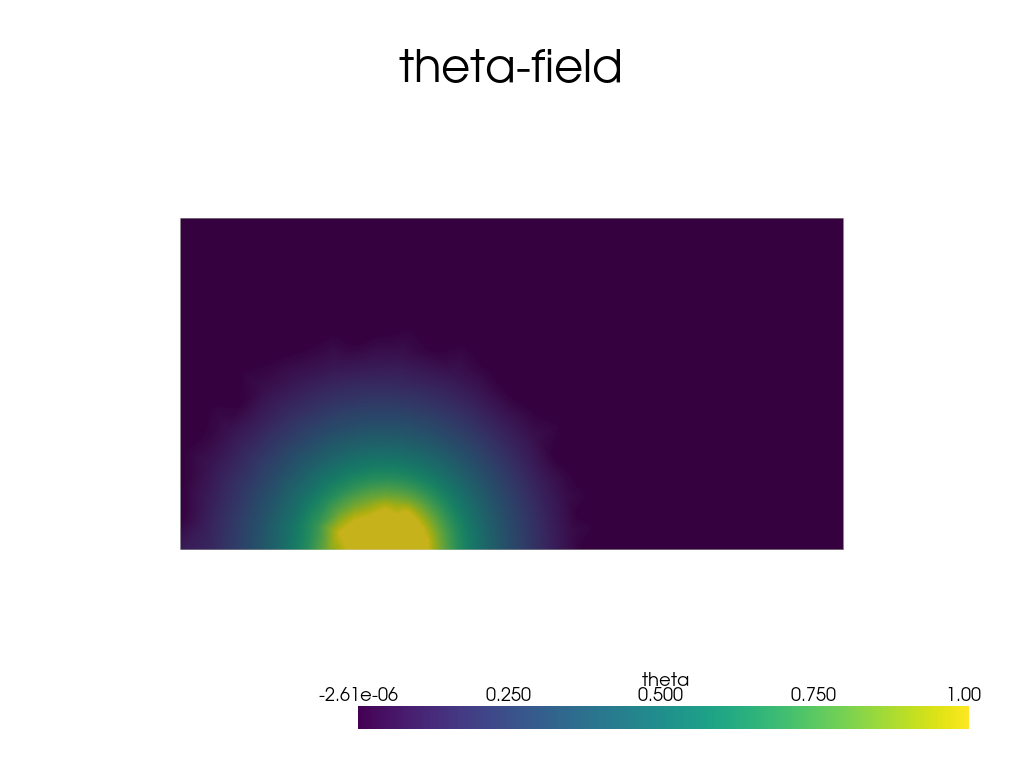

In [23]:
def create_theta_field(domain, crack_tip, R_int, R_ext):

    def tip_distance(x):
        return np.sqrt((x[0] - crack_tip[0])**2 + (x[1] - crack_tip[1])**2)

    V_theta = fem.functionspace(domain, ("Lagrange", 1))

    # Define variational problem to define the theta-field.
    # We solve a simple laplacian
    theta, theta_ = ufl.TrialFunction(V_theta), ufl.TestFunction(V_theta)
    a = ufl.dot(ufl.grad(theta), ufl.grad(theta_)) * ufl.dx
    L = fem.Constant(domain, ScalarType(0.)) * theta_ * ufl.dx(domain=domain)

    # Set the BCs
    # Imposing 1 in the inner circle and zero in the outer circle
    dofs_inner = fem.locate_dofs_geometrical(V_theta, lambda x: tip_distance(x) < R_int)
    dofs_out = fem.locate_dofs_geometrical(V_theta, lambda x: tip_distance(x) > R_ext)
    bc_inner = fem.dirichletbc(ScalarType(1.), dofs_inner, V_theta)
    bc_out = fem.dirichletbc(ScalarType(0.), dofs_out, V_theta)
    bcs = [bc_out, bc_inner]

    # solve the problem
    problem = fem.petsc.LinearProblem(a, L, petsc_options_prefix="theta_", bcs=bcs,
                                      petsc_options={"ksp_type": "gmres", "pc_type": "gamg"})
    thetah = problem.solve()
    return thetah


crack_tip = np.array([Lcrack, 0])
crack_tangent = np.array([1, 0])
R_int = Lcrack / 4.
R_ext = Lcrack
domain = uh.function_space.mesh
thetah = create_theta_field(domain, crack_tip, R_int, R_ext)

# Plot theta
topology, cell_types, geometry = plot.vtk_mesh(thetah.function_space)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)
grid.point_data["theta"] = thetah.x.array.real
grid.set_active_scalars("theta")
plotter = pyvista.Plotter()
plotter.add_mesh(grid, show_edges=False)
plotter.add_title("theta-field")
plotter.view_xy()
if not pyvista.OFF_SCREEN:
    plotter.show()

From the scalar field, we define a vector field by multiplying by the tangent
vector to the crack: $t=[1,0]$.

Hence, we can compute the ERR with the formula
$$
G  = \int_\Omega \left(\sigma(\varepsilon(u))\cdot(\nabla u\nabla\theta)-\dfrac{1}{2}\sigma(\varepsilon(u))\cdot \varepsilon(u) \mathrm{div}(\theta)\,\right)\mathrm{dx}$$

In [24]:
Lx = 1.
Ly = 0.5
Lcrack = 0.3
crack_tip = np.array([Lcrack, 0])
crack_tangent = np.array([1, 0])
R_int = Lcrack / 4
R_ext = Lcrack
uh, energy, sigma_ufl = solve_elasticity(Lx=Lx, Ly=Ly, Lcrack=Lcrack, lc=.05,
                                         refinement_ratio=30, dist_min=.1, dist_max=1.0)

thetah = create_theta_field(uh.function_space.mesh, crack_tip, R_int, R_ext)
eps_ufl = ufl.sym(ufl.grad(uh))
theta_vector = ufl.as_vector([1., 0.]) * thetah
dx = ufl.dx(domain=uh.function_space.mesh)
first_term = ufl.inner(sigma_ufl, ufl.grad(uh) * ufl.grad(theta_vector)) * dx
second_term = - 0.5 * ufl.inner(sigma_ufl, eps_ufl) * ufl.div(theta_vector) * dx

# the factor 2 accounts for the symmetry: only half of the slab is meshed.
# each process assembles its own part of the integral
G_theta = 2 * uh.function_space.mesh.comm.allreduce(
    fem.assemble_scalar(fem.form(first_term + second_term)), op=MPI.SUM
)
print(f'The ERR computed with the G-theta method is {G_theta:2.4f}')

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 50%] Meshing curve 3 (Line)
Info    : [ 70%] Meshing curve 4 (Line)
Info    : [ 90%] Meshing curve 5 (Line)
Info    : Done meshing 1D (Wall 0.00319896s, CPU 0.005273s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00613329s, CPU 0.009752s)
Info    : 640 nodes 1283 elements
The potential energy for Lcrack=3.000e-01 is -4.070e-01
The ERR computed with the G-theta method is 2.9656


**Note:**
The $\theta$ field represents how the domain is "varied" to take the domain
derivative. It must be 1 on the tip and zero on the boundary of the domain. The
choice of the field is otherwise arbitrary. With the generation method above,
given the crack length `Lcrack`, the disk radius `R_ext` should be chosen such
that the disk does not intersect the boundary of the domain: `R_ext < Lcrack`.
The internal radius `R_int` can be chosen as a few times the mesh size at the
tip, for example.